<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-3-experiments-causality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiments and Causality

ANOVA can tell us that group means differ. Whether the difference is caused by the treatment depends on how the data were collected. In this notebook we look at what makes a study an experiment, at what random assignment does, and at four basic causal diagrams.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [ ]:
from matplotlib.patches import FancyBboxPatch

def draw_dag(nodes, edges, title="", size=(7, 2.6)):
    """nodes: {name: (x, y)}, edges: [(from, to), ...]"""
    fig, ax = plt.subplots(figsize=size)
    for name, (x, y) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - 0.13, y - 0.09), 0.26, 0.18, boxstyle="round,pad=0.02",
                                    facecolor="white", edgecolor="black"))
        ax.text(x, y, name, ha="center", va="center", fontsize=10)
    def edge_point(x, y, dx, dy, hw=0.15, hh=0.11):
        t = min(hw / abs(dx) if dx else np.inf, hh / abs(dy) if dy else np.inf)
        return x + t * dx, y + t * dy
    for a, b in edges:
        (x0, y0), (x1, y1) = nodes[a], nodes[b]
        dx, dy = x1 - x0, y1 - y0
        start = edge_point(x0, y0, dx, dy)
        end = edge_point(x1, y1, -dx, -dy)
        ax.annotate("", xy=end, xytext=start,
                    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5, shrinkA=0, shrinkB=0))
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.axis("off")
    ax.set_title(title, fontsize=12)
    plt.show()

## 1. Experiments and observational studies

In an **experiment**, the researcher assigns the levels of the factor (the **treatments**) to the experimental units, ideally at random. In an **observational study**, the units end up in the groups on their own, and the researcher only observes them.

A regional bank is choosing one of three training formats for new tellers: online modules, classroom training, or job shadowing. The bank randomly assigns new tellers to the formats and, after 30 days, records the average time each teller needs to process a transaction. This is an experiment:

- the **response variable** is the processing time;
- the **factor** is the training format;
- the **treatments** are online modules, classroom training, and job shadowing;
- the **experimental units** are the tellers.

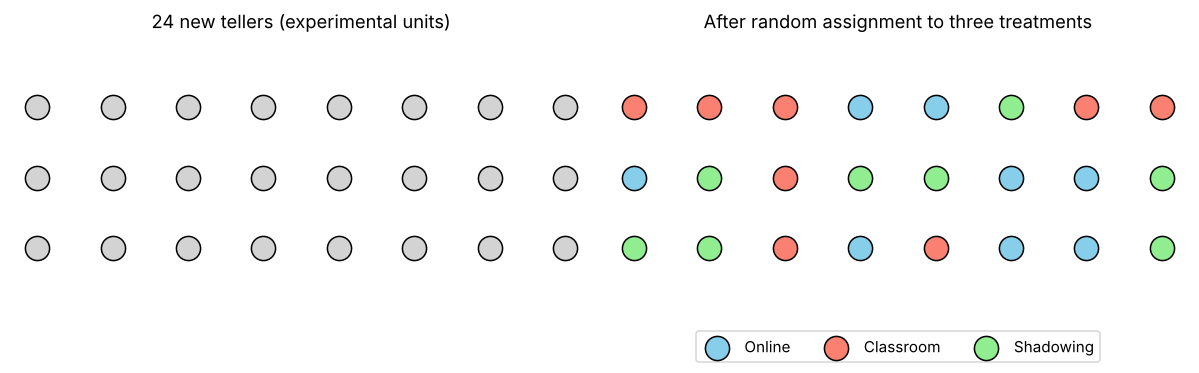

In [ ]:
rng = np.random.default_rng(5)
cols = {"Online": "skyblue", "Classroom": "salmon", "Shadowing": "lightgreen"}
labels = rng.permutation(np.repeat(list(cols), 8))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
xy = np.array([(i % 8, i // 8) for i in range(24)])
axes[0].scatter(xy[:, 0], xy[:, 1], s=250, color="lightgray", edgecolor="black")
axes[0].set_title("24 new tellers (experimental units)")
for j, (t, c) in enumerate(cols.items()):
    idx = np.where(labels == t)[0]
    axes[1].scatter(xy[idx, 0], xy[idx, 1], s=250, color=c, edgecolor="black", label=t)
axes[1].set_title("After random assignment to three treatments")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3)
for ax in axes: ax.axis("off"); ax.set_ylim(-1, 3)
plt.tight_layout(); plt.show()

The **experimental unit** is whatever was randomized. If the bank assigned whole cohorts of eight tellers to a format, the unit would be the cohort. Tellers trained together share a trainer and a classroom, so their processing times are related, and the study has as many independent observations as cohorts, not tellers.

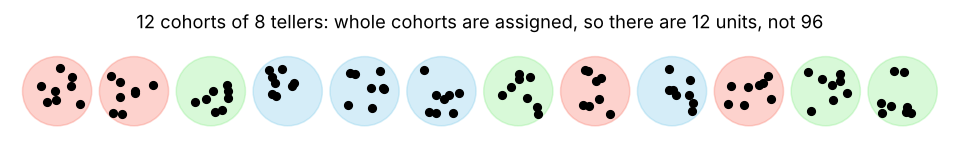

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3))
rng = np.random.default_rng(7); fmt = rng.permutation(np.repeat(list(cols), 4))
for c in range(12):
    cx = c * 1.0
    pts = rng.uniform(-0.3, 0.3, size=(8, 2))
    ax.add_patch(plt.Circle((cx, 0), 0.45, color=cols[fmt[c]], alpha=0.35))
    ax.scatter(cx + pts[:, 0], pts[:, 1], s=25, color="black")
ax.set_xlim(-0.6, 11.6); ax.set_ylim(-0.7, 0.7); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("12 cohorts of 8 tellers: whole cohorts are assigned, so there are 12 units, not 96")
plt.show()

Three principles of experimental design:

- **Randomization:** treatments are assigned to units at random.
- **Replication:** each treatment is applied to several units, so we can see the variation within treatments.
- **Control:** other conditions are kept the same across treatments, for example the same type of transactions for all tellers.

## 2. What random assignment does

Suppose a company offers an optional training course that has **no effect** at all on productivity. Employees differ in motivation, which nobody measures, and motivated employees are more productive. Compare two ways of deciding who takes the course.

In [ ]:
def one_study(design, rng, n=200):
    motivation = rng.normal(0, 1, n)
    productivity = 50 + 5 * motivation + rng.normal(0, 5, n)
    if design == "self-selection":
        takes_course = motivation + rng.normal(0, 1, n) > 0
    else:
        takes_course = rng.permutation(np.repeat([True, False], n // 2))
    return motivation, productivity, takes_course

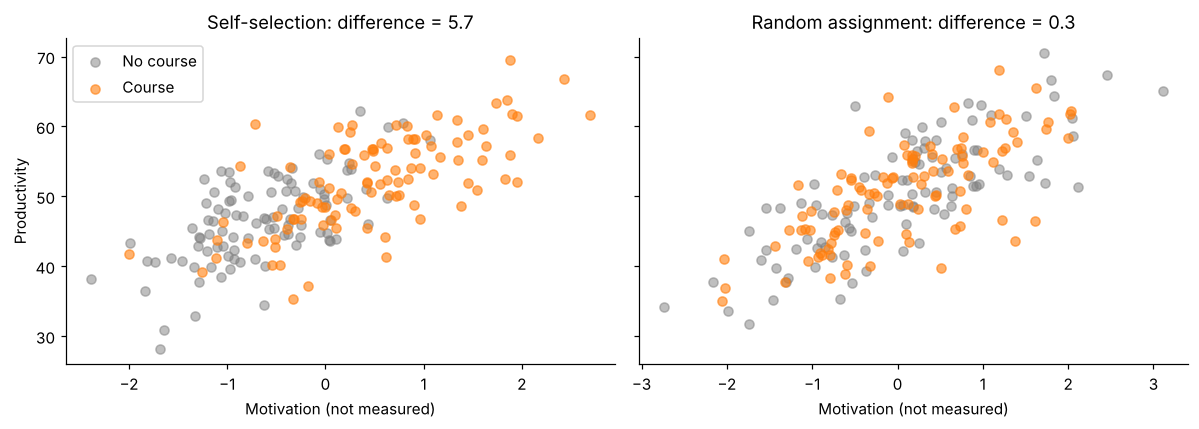

In [ ]:
rng = np.random.default_rng(5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, design in zip(axes, ["self-selection", "random assignment"]):
    m, p, t = one_study(design, rng)
    ax.scatter(m[~t], p[~t], alpha=0.5, color="gray", label="No course")
    ax.scatter(m[t], p[t], alpha=0.6, color="tab:orange", label="Course")
    ax.set_title(f"{design.capitalize()}: difference = {p[t].mean() - p[~t].mean():.1f}")
    ax.set_xlabel("Motivation (not measured)")
axes[0].set_ylabel("Productivity"); axes[0].legend(); plt.tight_layout(); plt.show()

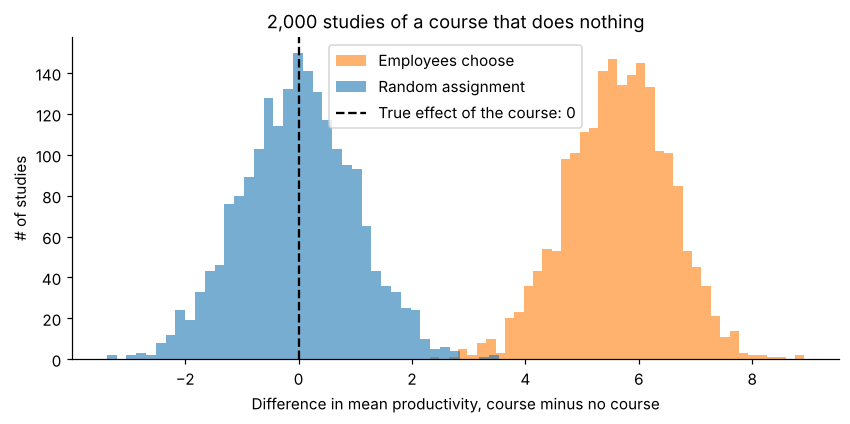

Average difference when employees choose:  5.63
Average difference with random assignment: -0.01


In [ ]:
rng = np.random.default_rng(10)
diff = {d: [] for d in ["self-selection", "random assignment"]}
for d in diff:
    for _ in range(2000):
        m, p, t = one_study(d, rng); diff[d].append(p[t].mean() - p[~t].mean())
plt.figure(figsize=(9, 3.8))
plt.hist(diff["self-selection"], bins=40, alpha=0.6, color="tab:orange", label="Employees choose")
plt.hist(diff["random assignment"], bins=40, alpha=0.6, color="tab:blue", label="Random assignment")
plt.axvline(0, color="black", ls="--", label="True effect of the course: 0")
plt.xlabel("Difference in mean productivity, course minus no course"); plt.ylabel("# of studies")
plt.title("2,000 studies of a course that does nothing"); plt.legend(); plt.show()
print(f"Average difference when employees choose:  {np.mean(diff['self-selection']):.2f}")
print(f"Average difference with random assignment: {np.mean(diff['random assignment']):.2f}")

When employees choose, the motivated ones take the course, and the course group looks more productive although the course does nothing. With random assignment, motivation is spread evenly between the groups on average, and the difference centers on the true effect, zero.

Random assignment makes the groups similar on average in **every** other variable, including the ones nobody measured. That is why a difference in means from a randomized experiment can be read as an effect of the treatment, while the same difference from observational data cannot.

## 3. Four causal diagrams

An arrow means "has a causal effect on".

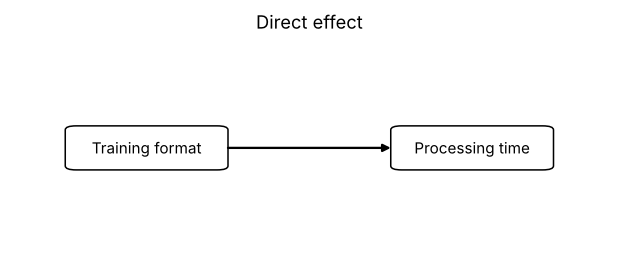

In [ ]:
draw_dag({"Training format": (0.2, 0.5), "Processing time": (0.8, 0.5)},
         [("Training format", "Processing time")], "Direct effect")

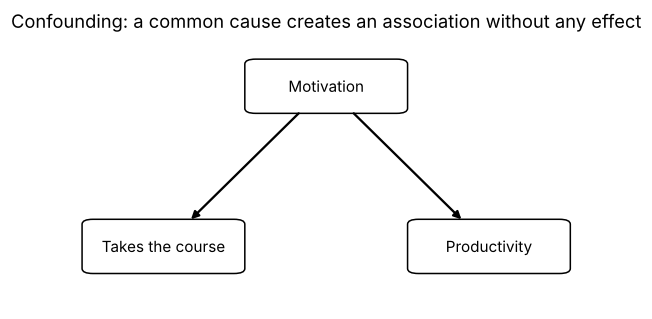

In [ ]:
draw_dag({"Motivation": (0.5, 0.85), "Takes the course": (0.2, 0.2), "Productivity": (0.8, 0.2)},
         [("Motivation", "Takes the course"), ("Motivation", "Productivity")],
         "Confounding: a common cause creates an association without any effect", size=(7, 3.2))

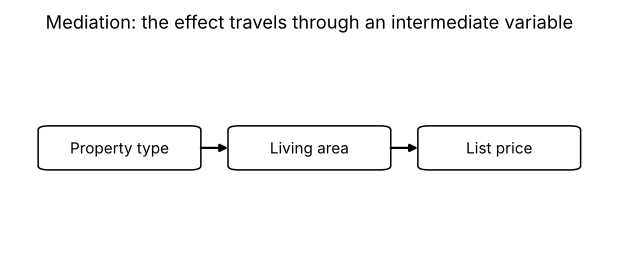

In [ ]:
draw_dag({"Property type": (0.15, 0.5), "Living area": (0.5, 0.5), "List price": (0.85, 0.5)},
         [("Property type", "Living area"), ("Living area", "List price")],
         "Mediation: the effect travels through an intermediate variable")

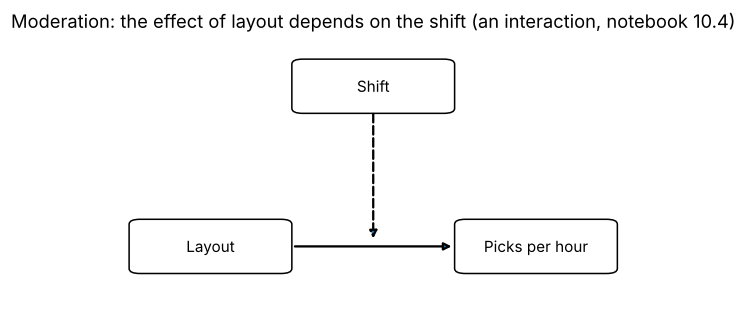

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
from matplotlib.patches import FancyBboxPatch
for name, (x, y) in {"Layout": (0.2, 0.2), "Picks per hour": (0.8, 0.2), "Shift": (0.5, 0.85)}.items():
    ax.add_patch(FancyBboxPatch((x - 0.13, y - 0.09), 0.26, 0.18, boxstyle="round,pad=0.02", facecolor="white", edgecolor="black"))
    ax.text(x, y, name, ha="center", va="center")
ax.annotate("", xy=(0.65, 0.2), xytext=(0.35, 0.2), arrowprops=dict(arrowstyle="-|>", lw=1.5))
ax.annotate("", xy=(0.5, 0.22), xytext=(0.5, 0.75), arrowprops=dict(arrowstyle="-|>", lw=1.5, ls="--"))
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.axis("off")
ax.set_title("Moderation: the effect of layout depends on the shift (an interaction, notebook 10.4)")
plt.show()

**Question to you:** in which of these diagrams does random assignment of the treatment help? Why does a confounder lose its influence under random assignment, while a mediator does not?

## 4. The smoking debate

In the reading "A Smoke-Filled Debate" from *The Book of Why*, the same questions were argued over decades. Smokers got lung cancer far more often than nonsmokers, but no one could randomly assign people to smoke. R. A. Fisher argued that the association could come from a confounder: an inherited genotype that makes people both more likely to smoke and more likely to develop lung cancer.

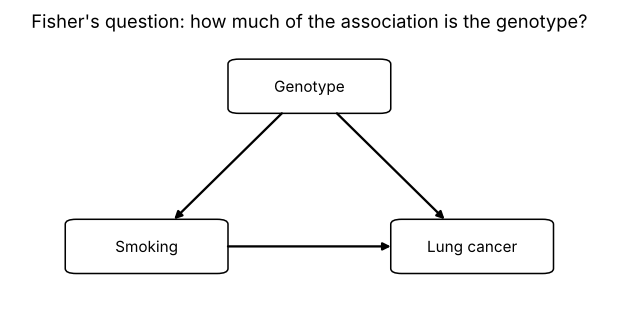

In [ ]:
draw_dag({"Genotype": (0.5, 0.85), "Smoking": (0.2, 0.2), "Lung cancer": (0.8, 0.2)},
         [("Genotype", "Smoking"), ("Genotype", "Lung cancer"), ("Smoking", "Lung cancer")],
         "Fisher's question: how much of the association is the genotype?", size=(7, 3.2))

Jerome Cornfield answered with an argument about how strong such a confounder would have to be. As you read, notice how the question was settled without a randomized experiment, and what that required.